# 🔬 Experimento 2026-10: Filtrado Circular en el Espectro de Fourier

**Proyecto:** `<mx-img />` - Carga progresiva de imágenes vía streaming.  
**Objetivo de referencia ([GOALS-es.md](../../GOALS-es.md)):**
- *Se transmite progresivamente el espectro de Fourier de las imágenes.*
- *Opción de manejar el porcentaje o peso de datos a transferir de forma dinámica.*

En este cuaderno analizaremos y replicaremos el filtrado progresivo mediante una **máscara circular de radio variable** sobre la transformada de Fourier bidimensional ($2D\text{-FFT}$).

---
### Flujo de etapas (Stages):
1. **Stage 1:** Carga y visualización de la imagen original (`image.jpeg`).
2. **Stage 2:** Cálculo y visualización del espectro de Fourier (magnitud logarítmica).
3. **Stage 3:** Generación y visualización de la máscara de corte circular.
4. **Stage 4:** Aplicación del corte en el espectro frecuencial.
5. **Stage 5:** Reconstrucción espacial mediante la transformada inversa (2D-IFFT).
6. **Comparativa Multi-Radio:** Simulación de los 3 niveles de progresión (R=35, R=80, R=200).
7. **Control Interactivo:** Slider en vivo para experimentar dinámicamente con cualquier radio.


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de visualización
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'

# Ubicación de la imagen de prueba (búsqueda robusta compatible con cualquier CWD o kernel)
candidate_paths = [
    '../images/image.jpeg',
    'images/image.jpeg',
    'experiments/images/image.jpeg',
    '/Users/francomolochegarcia/dev/mx-img/experiments/images/image.jpeg'
]
img_path = next((p for p in candidate_paths if os.path.exists(p)), None)
assert img_path is not None, f"No se encontró la imagen en ninguna ruta: {candidate_paths}"
print(f"✅ Entorno listo y archivo verificado: {img_path}")


✅ Entorno listo y archivo verificado: images/image.jpeg


## 📸 Stage 1: Imagen Original (`image.jpeg`)
Cargamos la imagen en escala de grises para el procesamiento matricial en dos dimensiones $f(x, y)$.


Dimensiones de la imagen: 800 × 780 píxeles
Rango de valores: min=0, max=196, tipo=uint8


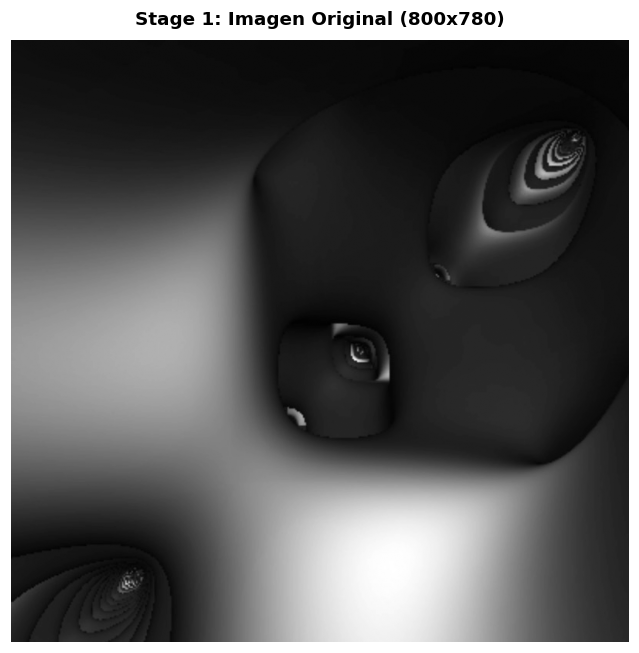

In [2]:
# Carga en escala de grises
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
h, w = img.shape

print(f"Dimensiones de la imagen: {w} × {h} píxeles")
print(f"Rango de valores: min={img.min()}, max={img.max()}, tipo={img.dtype}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap='gray')
ax.set_title(f"Stage 1: Imagen Original ({w}x{h})", fontsize=12, fontweight='bold', pad=10)
ax.axis('off')
plt.tight_layout()
plt.show()


## 🌌 Stage 2: Espectro de Fourier (2D-FFT)
Calculamos la Transformada Rápida de Fourier 2D:
$$F(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x, y) e^{-j 2\pi \left(\frac{ux}{M} + \frac{vy}{N}\right)}$$

Utilizamos `fftshift` para centrar las bajas frecuencias (que concentran la mayor parte de la energía luminosa y la forma global) en el centro $(crow, ccol)$, mientras que las altas frecuencias (bordes y textura fina) quedan en la periferia.  
Visualizamos la magnitud en escala logarítmica: $S(u, v) = 20 \cdot \log(1 + |F(u, v)|)$.


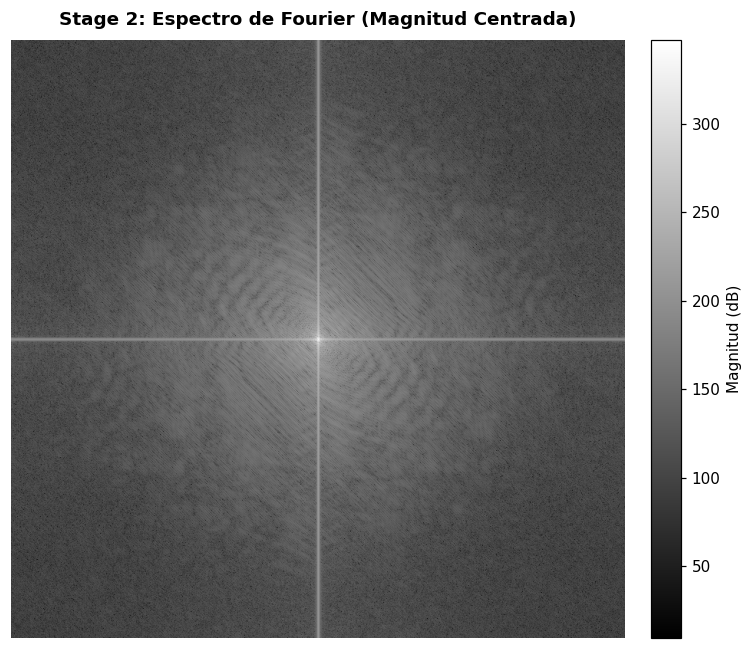

In [3]:
# Cálculo de la FFT 2D
f_transform = np.fft.fft2(img.astype(np.float64))
f_shift = np.fft.fftshift(f_transform)

# Espectro de magnitud logarítmica
magnitude_spectrum = 20 * np.log(1 + np.abs(f_shift))

fig, ax = plt.subplots(figsize=(7, 6))
cax = ax.imshow(magnitude_spectrum, cmap='gray')
ax.set_title("Stage 2: Espectro de Fourier (Magnitud Centrada)", fontsize=12, fontweight='bold', pad=10)
ax.axis('off')
cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Magnitud (dB)", fontsize=10)
plt.tight_layout()
plt.show()


## ⭕ Stage 3: Máscara del Corte Circular (Filtro Paso Bajo)
Creamos una máscara binaria circular $M(u, v)$ de radio $R$ centrada en $(crow, ccol)$:
$$M(u, v) = \begin{cases} 1 & \text{si } \sqrt{(u - crow)^2 + (v - ccol)^2} \le R \\ 0 & \text{en caso contrario} \end{cases}$$


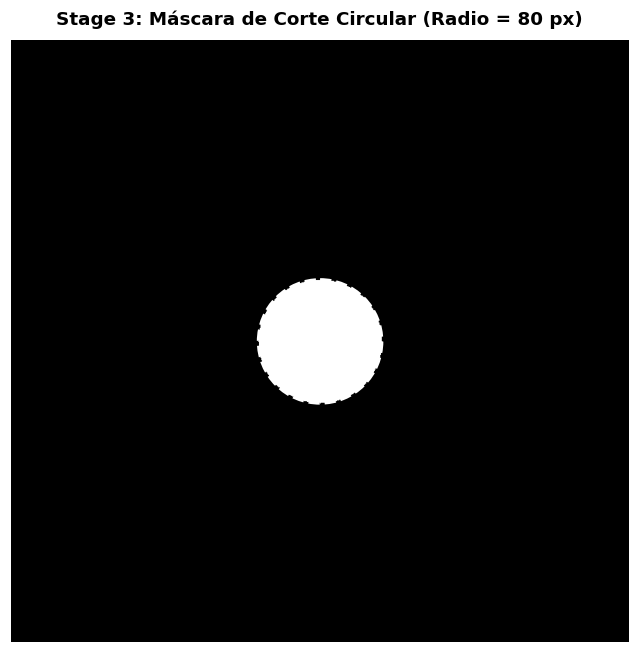

In [4]:
def create_circular_mask(height, width, radius, center=None):
    if center is None:
        center = (height // 2, width // 2)
    cy, cx = center
    y, x = np.ogrid[:height, :width]
    dist_from_center = np.sqrt((x - cx)**2 + (y - cy)**2)
    return (dist_from_center <= radius).astype(np.float64)

radius = 80
crow, ccol = h // 2, w // 2
mask = create_circular_mask(h, w, radius, center=(crow, ccol))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(mask, cmap='gray')

# Dibujar el contorno blanco del corte circular
circ = plt.Circle((ccol, crow), radius, color='white', fill=False, linewidth=2, linestyle='--')
ax.add_patch(circ)

ax.set_title(f"Stage 3: Máscara de Corte Circular (Radio = {radius} px)", fontsize=12, fontweight='bold', pad=10)
ax.axis('off')
plt.tight_layout()
plt.show()


## ✂️ Stage 4: Espectro Cortado
Multiplicamos el espectro centrado por la máscara circular:
$$F_{\text{cut}}(u, v) = F_{\text{shift}}(u, v) \cdot M(u, v)$$

Esto elimina las componentes de alta frecuencia más allá del radio $R$, simulando el envío de solo una porción compacta de frecuencias.


📊 Coeficientes frecuenciales conservados: 3.22% (20,081 de 624,000 píxeles)
⚡ Energía espectral retenida: 99.79% de la energía total


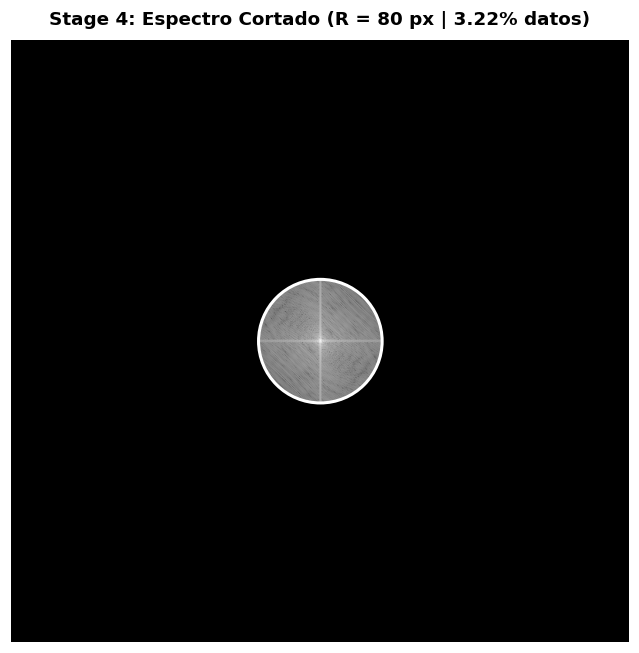

In [5]:
# Aplicación del corte frecuencial
f_shift_cut = f_shift * mask

# Magnitud del espectro cortado
magnitude_cut = 20 * np.log(1 + np.abs(f_shift_cut))

# Métricas de datos y energía
total_energy = np.sum(np.abs(f_shift)**2)
retained_energy = np.sum(np.abs(f_shift_cut)**2)
energy_pct = (retained_energy / total_energy) * 100
coeffs_pct = (np.count_nonzero(mask) / (h * w)) * 100

print(f"📊 Coeficientes frecuenciales conservados: {coeffs_pct:.2f}% ({np.count_nonzero(mask):,} de {h*w:,} píxeles)")
print(f"⚡ Energía espectral retenida: {energy_pct:.2f}% de la energía total")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(magnitude_cut, cmap='gray')

# Borde circular blanco (como en la referencia)
circ = plt.Circle((ccol, crow), radius, color='white', fill=False, linewidth=2)
ax.add_patch(circ)

ax.set_title(f"Stage 4: Espectro Cortado (R = {radius} px | {coeffs_pct:.2f}% datos)", fontsize=12, fontweight='bold', pad=10)
ax.axis('off')
plt.tight_layout()
plt.show()


## 🔄 Stage 5: Transformada Inversa (2D-IFFT) y Resultado Reconstruido
Invertimos el centrado con `ifftshift` y aplicamos la transformada inversa:
$$f_{\text{rec}}(x, y) = \mathcal{F}^{-1}\{F_{\text{cut}}(u, v)\}$$
Tomamos la parte real, acotamos al rango $[0, 255]$ y comparamos con la imagen original.


📉 Error Cuadrático Medio (MSE): 11.99
📈 PSNR (Peak Signal-to-Noise Ratio): 37.34 dB


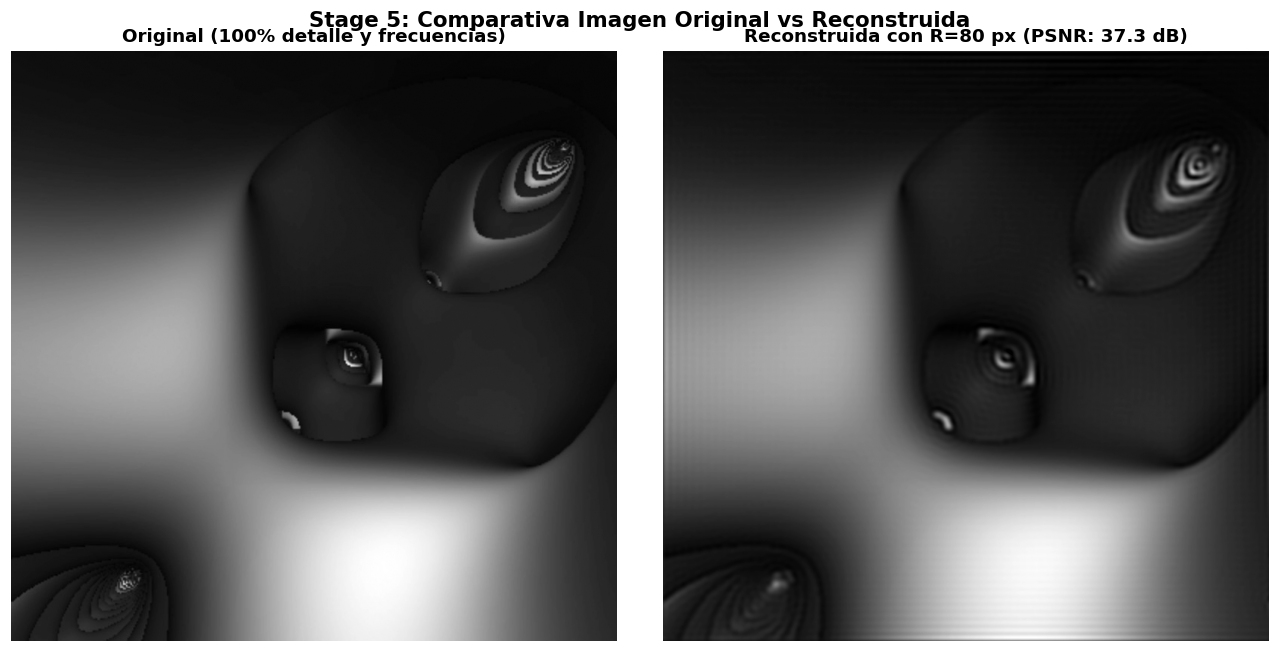

In [6]:
# Reconstrucción espacial con IFFT
f_ishift = np.fft.ifftshift(f_shift_cut)
img_back = np.fft.ifft2(f_ishift)
img_reconstructed = np.clip(np.real(img_back), 0, 255).astype(np.uint8)

# Métricas de fidelidad visual
mse = np.mean((img.astype(float) - img_reconstructed.astype(float))**2)
psnr = 10 * np.log10((255**2) / (mse + 1e-10))

print(f"📉 Error Cuadrático Medio (MSE): {mse:.2f}")
print(f"📈 PSNR (Peak Signal-to-Noise Ratio): {psnr:.2f} dB")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img, cmap='gray')
axes[0].set_title("Original (100% detalle y frecuencias)", fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(img_reconstructed, cmap='gray')
axes[1].set_title(f"Reconstruida con R={radius} px (PSNR: {psnr:.1f} dB)", fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.suptitle("Stage 5: Comparativa Imagen Original vs Reconstruida", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 🎛️ Réplica Exacta de las Referencias: Cuadrícula 2×2
Implementamos la función que reproduce con exactitud los 4 cuadrantes de las capturas:
- **Arriba-Izquierda:** Espectro de Fourier completo
- **Arriba-Derecha:** Imagen original
- **Abajo-Izquierda:** Espectro cortado con el círculo blanco del radio
- **Abajo-Derecha:** Imagen reconstruida mediante IFFT

Generamos las 3 etapas mostradas por el usuario:
1. **Radio pequeño ($R=35$ px):** Imagen base/borrosa, transfiere aprox. $0.6\%$ de coeficientes.
2. **Radio mediano ($R=80$ px):** Definición intermedia de contornos y montañas, aprox. $3.2\%$ de coeficientes.
3. **Radio amplio ($R=200$ px):** Gran nitidez y detalle fino, aprox. $20.1\%$ de coeficientes.


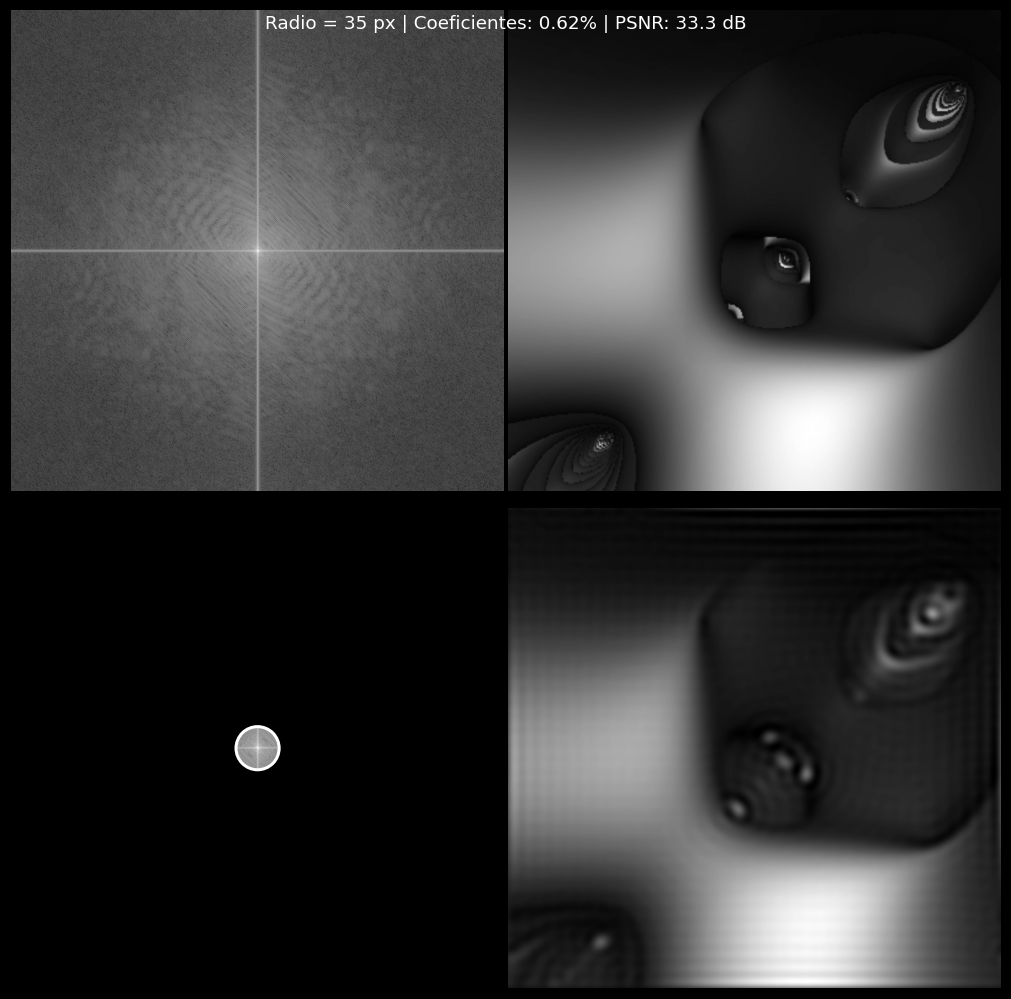

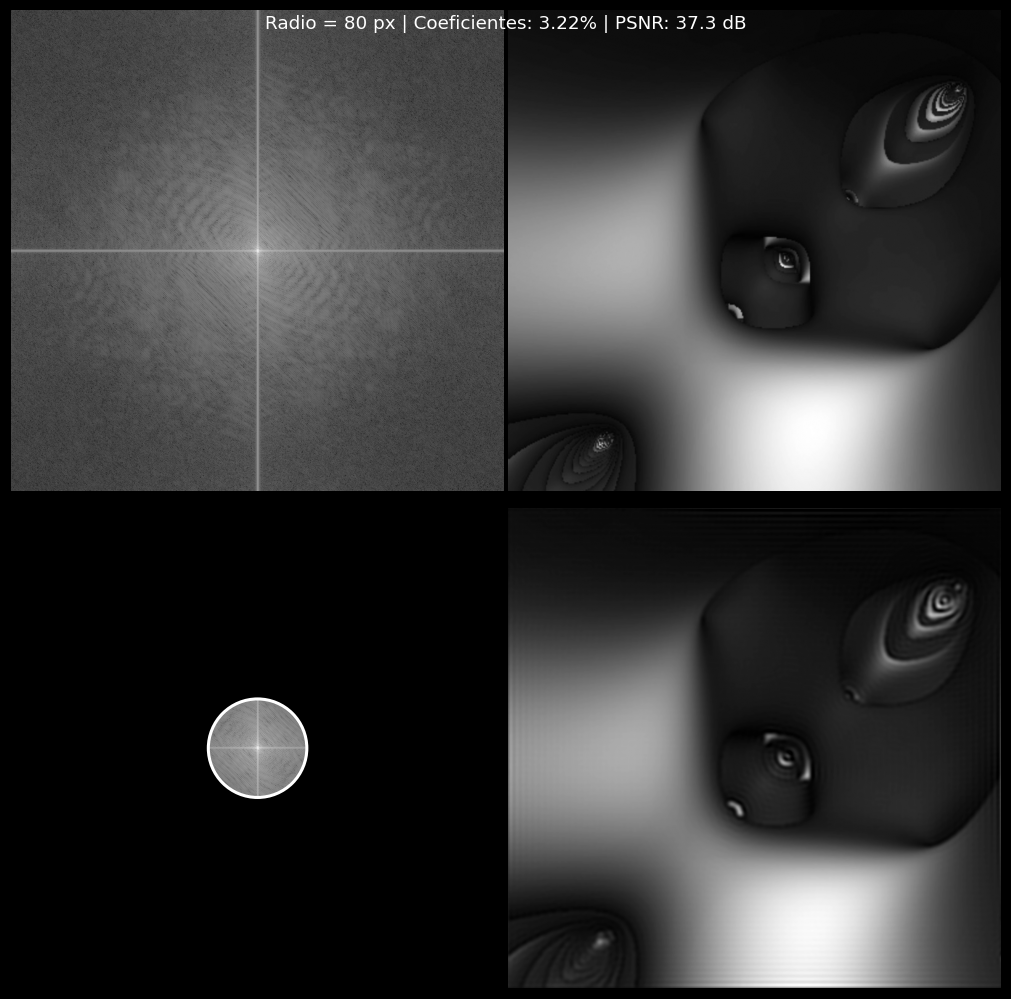

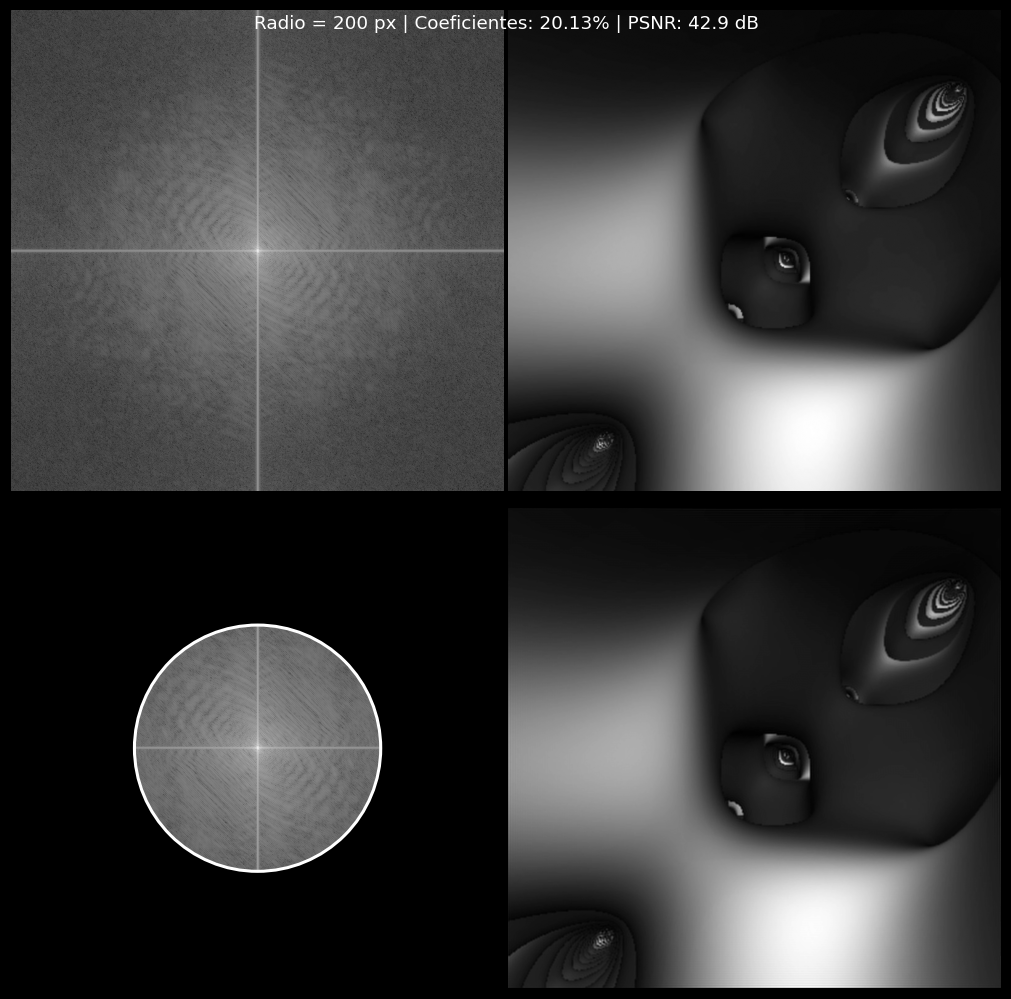

In [7]:
def render_experiment_2x2(r):
    current_mask = create_circular_mask(h, w, r, center=(crow, ccol))
    f_cut = f_shift * current_mask
    mag_cut = 20 * np.log(1 + np.abs(f_cut))
    
    inv_shift = np.fft.ifftshift(f_cut)
    rec_img = np.clip(np.real(np.fft.ifft2(inv_shift)), 0, 255).astype(np.uint8)
    
    pct_coeffs = (np.count_nonzero(current_mask) / (h * w)) * 100
    cur_mse = np.mean((img.astype(float) - rec_img.astype(float))**2)
    cur_psnr = 10 * np.log10((255**2) / (cur_mse + 1e-10))
    
    fig, axes = plt.subplots(2, 2, figsize=(9, 9), facecolor='black')
    
    # 1. Espectro completo
    axes[0, 0].imshow(magnitude_spectrum, cmap='gray')
    axes[0, 0].axis('off')
    
    # 2. Imagen original
    axes[0, 1].imshow(img, cmap='gray')
    axes[0, 1].axis('off')
    
    # 3. Espectro cortado con contorno circular blanco
    axes[1, 0].imshow(mag_cut, cmap='gray')
    circ = plt.Circle((ccol, crow), r, color='white', fill=False, linewidth=2)
    axes[1, 0].add_patch(circ)
    axes[1, 0].axis('off')
    
    # 4. Imagen reconstruida
    axes[1, 1].imshow(rec_img, cmap='gray')
    axes[1, 1].axis('off')
    
    fig.subplots_adjust(wspace=0.01, hspace=0.01, left=0, right=1, bottom=0, top=1)
    plt.suptitle(f"Radio = {r} px | Coeficientes: {pct_coeffs:.2f}% | PSNR: {cur_psnr:.1f} dB",
                 color='white', fontsize=12, y=0.99)
    plt.show()

# Ejecutamos las 3 variaciones de la referencia del usuario
for test_r in [35, 80, 200]:
    render_experiment_2x2(test_r)


## 🎚️ Modo Interactivo con Slider (Para Jupyter)
Ejecuta la siguiente celda en Jupyter Notebook o JupyterLab para controlar el radio $R$ interactivamente con un control deslizante.


In [ ]:
try:
    from ipywidgets import interact, IntSlider
    slider = IntSlider(min=5, max=int(min(h, w) // 2), step=5, value=80, description='Radio R:')
    interact(render_experiment_2x2, r=slider);
except ImportError:
    print("ipywidgets no disponible en este entorno.")
